<a href="https://colab.research.google.com/github/luzferrin/Clasificacion-de-modelos-para-casos-de-diabetes-tipo-2/blob/main/Diabetes_6_modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Instala dependencias**

In [ ]:
%pip -q install catboost==1.2.10 openpyxl
%pip -q install rtdl --no-deps

### **Importaciones, configuración y dataset**

In [ ]:
import os
import json
import random
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import rtdl
import torch

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    log_loss,
    confusion_matrix,
    roc_curve,
    auc,
)

from catboost import CatBoostClassifier
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from google.colab import files


# Configuración general
SEED = 2026
N_SPLITS = 10
MAX_EPOCHS = 100
MAX_ITERATIONS = 100
EARLY_STOPPING_PATIENCE = 20

MLP_EPOCHS = 24
MLP_BATCH_SIZE = 20
MLP_LEARNING_RATE = 0.01

RESNET_BATCH_SIZE = 128
DEVICE = torch.device("cpu")

OUTPUT_DIR = Path("resultados_6_modelos_10fold")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = [
    "Árbol de decisión",
    "Bosque aleatorio",
    "MLP",
    "SVM",
    "ResNet",
    "CatBoost",
]

MODEL_COLORS = {
    "Árbol de decisión": "#A9D9C1",
    "Bosque aleatorio": "#235940",
    "MLP": "#52A880",
    "SVM": "#77BF9B",
    "ResNet": "#458265",
    "CatBoost": "#A6E86A",
}

MODEL_SHORT = {
    "Árbol de decisión": "Árbol",
    "Bosque aleatorio": "Bosque",
    "MLP": "MLP",
    "SVM": "SVM",
    "ResNet": "ResNet",
    "CatBoost": "CatBoost",
}


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)


# Cargar el archivo
uploaded = files.upload()

valid_files = [
    name
    for name in uploaded
    if name.lower().endswith((".xlsx", ".xls", ".csv"))
]

if len(valid_files) != 1:
    raise ValueError("Sube un solo archivo .xlsx, .xls o .csv.")

file_name = valid_files[0]

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)
else:
    df = pd.read_excel(file_name)


# Variable objetivo y predictores
TARGET = "Type-2 Diabetic"

FEATURES = [
    "No. of Pregnancy",
    "Age",
    "BMI",
    "BP(Systolic)",
    "BP(Diastolic)",
    "DiabetesPedigreeFunction",
    "Insulin",
    "Skin Thickness(mm)",
    "Glucose",
]

missing_columns = [
    column
    for column in [TARGET, *FEATURES]
    if column not in df.columns
]

if missing_columns:
    raise ValueError(f"Faltan columnas en el archivo: {missing_columns}")

# Convierte las celdas vacías en NaN para que el preprocesamiento
# de cada pliegue pueda imputarlas usando solo el conjunto de entrenamiento.
X = (
    df[FEATURES]
    .apply(pd.to_numeric, errors="coerce")
    .copy()
    .reset_index(drop=True)
)

y = pd.to_numeric(df[TARGET], errors="coerce")

if y.isna().any() or not y.isin([0, 1]).all():
    raise ValueError(
        "La columna 'Type-2 Diabetic' debe contener únicamente etiquetas "
        "0 y 1, sin valores faltantes."
    )

y = y.astype(int).reset_index(drop=True)


# Verificar cantidad de registros y distribución de clases
class_counts = y.value_counts().sort_index().to_dict()
expected_class_counts = {0: 119, 1: 377}

if len(df) != 496 or class_counts != expected_class_counts:
    raise ValueError(
        "Se esperaba un archivo de 496 filas "
        "(119 de clase 0 y 377 de clase 1), "
        f"pero se recibió {len(df)} filas y esta distribución: {class_counts}."
    )


# Reportar valores faltantes; se conservan para la imputación dentro de cada pliegue
missing_by_column = X.isna().sum()
missing_by_column = missing_by_column[missing_by_column > 0]

print(f"Archivo cargado: {file_name}")
print(f"Filas para el análisis: {len(df)}")
print(f"Casos sin diabetes (clase 0): {class_counts[0]}")
print(f"Casos con diabetes tipo 2 (clase 1): {class_counts[1]}")

if missing_by_column.empty:
    print("No se encontraron valores faltantes en los predictores.")
else:
    print("Valores faltantes conservados para el preprocesamiento por pliegue:")
    display(missing_by_column.rename("Cantidad").to_frame())

Saving Diabetes_type_sin_duplicados_insulin_faltante.xlsx to Diabetes_type_sin_duplicados_insulin_faltante.xlsx
Archivo cargado: Diabetes_type_sin_duplicados_insulin_faltante.xlsx
Filas para el análisis: 496
Casos sin diabetes (clase 0): 119
Casos con diabetes tipo 2 (clase 1): 377
Valores faltantes conservados para el preprocesamiento por pliegue:


,Cantidad
Insulin,358


### **Divisiones, regla y funciones de los modelos**

In [ ]:
# Divisiones, regla de glucosa, preprocesamiento y funciones de los modelos

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    log_loss,
)
from catboost import CatBoostClassifier
import copy


# 1. Pliegues externos compartidos por los seis modelos
# Cada pliegue externo reserva aproximadamente 10% para prueba.
# Del 90% restante, se reserva aproximadamente 10% para validación:
# entrenamiento 80%, validación 10% y prueba 10%.

outer_cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED,
)

splits = []

for fold, (train_validation_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1,
):
    train_idx, validation_idx = train_test_split(
        train_validation_idx,
        test_size=1 / 9,
        random_state=SEED + fold,
        stratify=y.iloc[train_validation_idx],
    )

    splits.append(
        (
            np.asarray(train_idx),
            np.asarray(validation_idx),
            np.asarray(test_idx),
        )
    )

print(f"Se prepararon {len(splits)} pliegues compartidos.")
print(
    "Tamaños del primer pliegue:",
    f"entrenamiento={len(splits[0][0])},",
    f"validación={len(splits[0][1])},",
    f"prueba={len(splits[0][2])}",
)


# 2. Regla experimental basada en glucosa plasmática en ayunas
# <100 mg/dL: puntuación 0
# 100–125 mg/dL: puntuación 0.5
# >=126 mg/dL: puntuación 1
#
# Esta función devuelve puntuaciones. La lógica que aplica la regla
# a las predicciones se incorpora en el bloque 4.

def glucose_rule(data):
    if "Glucose" not in data.columns:
        raise ValueError("No se encontró la columna 'Glucose'.")

    glucose = pd.to_numeric(data["Glucose"], errors="coerce")

    if glucose.isna().any():
        raise ValueError(
            "Hay valores faltantes en Glucose; la regla requiere "
            "un valor de glucosa para cada registro."
        )

    rule_score = np.select(
        [
            glucose < 100,
            (glucose >= 100) & (glucose < 126),
            glucose >= 126,
        ],
        [0.0, 0.5, 1.0],
        default=np.nan,
    )

    return np.asarray(rule_score, dtype=float)


# 3. Métricas por pliegue

def score_metrics(y_true, y_pred, y_score, rule_score):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    y_score = np.clip(np.asarray(y_score, dtype=float), 1e-7, 1 - 1e-7)
    rule_score = np.asarray(rule_score, dtype=float)

    covered = rule_score != 0.5
    rule_prediction = (rule_score >= 0.5).astype(int)

    if covered.any():
        rule_accuracy_covered = accuracy_score(
            y_true[covered],
            rule_prediction[covered],
        )
    else:
        rule_accuracy_covered = np.nan

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_pos": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0,
        ),
        "recall_pos": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0,
        ),
        "F1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "ROC_AUC": roc_auc_score(y_true, y_score),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "log_loss": log_loss(y_true, y_score, labels=[0, 1]),
        "rule_coverage": float(covered.mean()),
        "rule_accuracy_covered": rule_accuracy_covered,
    }


# 4. Preprocesamiento ajustado solo con el conjunto de entrenamiento
# La mediana y el escalador se calculan en x_train; luego se aplican
# a validación y prueba, sin usar esos datos para ajustar el preprocesador.

def fit_transform_features(x_train, x_validation, x_test, scale=True):
    imputer = SimpleImputer(strategy="median")

    x_train_imputed = imputer.fit_transform(x_train)
    x_validation_imputed = imputer.transform(x_validation)
    x_test_imputed = imputer.transform(x_test)

    scaler = None

    if scale:
        scaler = StandardScaler()
        x_train_processed = scaler.fit_transform(x_train_imputed)
        x_validation_processed = scaler.transform(x_validation_imputed)
        x_test_processed = scaler.transform(x_test_imputed)
    else:
        x_train_processed = x_train_imputed
        x_validation_processed = x_validation_imputed
        x_test_processed = x_test_imputed

    return (
        x_train_processed.astype(np.float32),
        x_validation_processed.astype(np.float32),
        x_test_processed.astype(np.float32),
        imputer,
        scaler,
    )


# 5. Función de entrenamiento y predicción para cada modelo

def fit_model(name, x_train, y_train, x_validation, y_validation, x_test, seed):
    y_train = np.asarray(y_train, dtype=int)
    y_validation = np.asarray(y_validation, dtype=int)

    details = {"seed": int(seed)}

    # Árbol de decisión
    if name == "Árbol de decisión":
        (
            xtr,
            xva,
            xte,
            imputer,
            scaler,
        ) = fit_transform_features(
            x_train,
            x_validation,
            x_test,
            scale=False,
        )

        model = DecisionTreeClassifier(
            max_depth=10,
            min_samples_split=5,
            random_state=seed,
        )
        model.fit(xtr, y_train)

        prediction = model.predict(xte).astype(int)
        probability = model.predict_proba(xte)[:, 1]

        details.update({
            "max_depth": 10,
            "min_samples_split": 5,
        })

    # Bosque aleatorio
    elif name == "Bosque aleatorio":
        (
            xtr,
            xva,
            xte,
            imputer,
            scaler,
        ) = fit_transform_features(
            x_train,
            x_validation,
            x_test,
            scale=False,
        )

        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            min_samples_split=5,
            random_state=seed,
            n_jobs=1,
        )
        model.fit(xtr, y_train)

        prediction = model.predict(xte).astype(int)
        probability = model.predict_proba(xte)[:, 1]

        details.update({
            "n_estimators": 100,
            "max_depth": 10,
            "min_samples_split": 5,
        })

    # SVM
    elif name == "SVM":
        (
            xtr,
            xva,
            xte,
            imputer,
            scaler,
        ) = fit_transform_features(
            x_train,
            x_validation,
            x_test,
            scale=True,
        )

        model = SVC(
            kernel="rbf",
            probability=True,
            random_state=seed,
        )
        model.fit(xtr, y_train)

        prediction = model.predict(xte).astype(int)
        probability = model.predict_proba(xte)[:, 1]

        details.update({
            "kernel": "rbf",
            "probability": True,
        })

    # MLP: red neuronal multicapa para datos tabulares
    elif name == "MLP":
        (
            xtr,
            xva,
            xte,
            imputer,
            scaler,
        ) = fit_transform_features(
            x_train,
            x_validation,
            x_test,
            scale=True,
        )

        seed_everything(seed)

        model = nn.Sequential(
            nn.Linear(xtr.shape[1], 12),
            nn.ReLU(),
            nn.Linear(12, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
        ).to(DEVICE)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=MLP_LEARNING_RATE,
        )
        loss_function = nn.BCEWithLogitsLoss()

        xtr_tensor = torch.tensor(xtr, dtype=torch.float32, device=DEVICE)
        ytr_tensor = torch.tensor(
            y_train.reshape(-1, 1),
            dtype=torch.float32,
            device=DEVICE,
        )

        generator = torch.Generator()
        generator.manual_seed(seed)

        train_loader = DataLoader(
            TensorDataset(xtr_tensor, ytr_tensor),
            batch_size=MLP_BATCH_SIZE,
            shuffle=True,
            generator=generator,
        )

        model.train()
        for _ in range(MLP_EPOCHS):
            for batch_x, batch_y in train_loader:
                optimizer.zero_grad()
                logits = model(batch_x)
                loss = loss_function(logits, batch_y)
                loss.backward()
                optimizer.step()

        model.eval()
        with torch.no_grad():
            xte_tensor = torch.tensor(
                xte,
                dtype=torch.float32,
                device=DEVICE,
            )
            logits = model(xte_tensor).cpu().numpy().ravel()
            probability = 1 / (1 + np.exp(-logits))

        prediction = (probability >= 0.5).astype(int)

        details.update({
            "hidden_layers": [12, 8],
            "activation": "ReLU",
            "optimizer": "Adam",
            "learning_rate": MLP_LEARNING_RATE,
            "epochs": MLP_EPOCHS,
            "batch_size": MLP_BATCH_SIZE,
        })

    # ResNet tabular
    elif name == "ResNet":
        (
            xtr,
            xva,
            xte,
            imputer,
            scaler,
        ) = fit_transform_features(
            x_train,
            x_validation,
            x_test,
            scale=True,
        )

        seed_everything(seed)

        model = rtdl.ResNet.make_baseline(
            d_in=xtr.shape[1],
            d_main=128,
            d_hidden=256,
            dropout_first=0.25,
            dropout_second=0.1,
            n_blocks=2,
            d_out=1,
        ).to(DEVICE)

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=0.001,
            weight_decay=0.0,
        )
        loss_function = nn.BCEWithLogitsLoss()

        xtr_tensor = torch.tensor(xtr, dtype=torch.float32, device=DEVICE)
        ytr_tensor = torch.tensor(
            y_train.reshape(-1, 1),
            dtype=torch.float32,
            device=DEVICE,
        )
        xva_tensor = torch.tensor(xva, dtype=torch.float32, device=DEVICE)
        yva_tensor = torch.tensor(
            y_validation.reshape(-1, 1),
            dtype=torch.float32,
            device=DEVICE,
        )

        generator = torch.Generator()
        generator.manual_seed(seed)

        train_loader = DataLoader(
            TensorDataset(xtr_tensor, ytr_tensor),
            batch_size=RESNET_BATCH_SIZE,
            shuffle=True,
            generator=generator,
        )

        best_state = copy.deepcopy(model.state_dict())
        best_validation_loss = float("inf")
        epochs_without_improvement = 0
        epochs_trained = 0

        for epoch in range(MAX_EPOCHS):
            model.train()

            for batch_x, batch_y in train_loader:
                optimizer.zero_grad()
                logits = model(batch_x).reshape(-1, 1)
                loss = loss_function(logits, batch_y)
                loss.backward()
                optimizer.step()

            model.eval()
            with torch.no_grad():
                validation_logits = model(xva_tensor).reshape(-1, 1)
                validation_loss = loss_function(
                    validation_logits,
                    yva_tensor,
                ).item()

            epochs_trained = epoch + 1

            if validation_loss < best_validation_loss:
                best_validation_loss = validation_loss
                best_state = copy.deepcopy(model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                break

        model.load_state_dict(best_state)
        model.eval()

        with torch.no_grad():
            xte_tensor = torch.tensor(
                xte,
                dtype=torch.float32,
                device=DEVICE,
            )
            logits = model(xte_tensor).reshape(-1).cpu().numpy()
            probability = 1 / (1 + np.exp(-logits))

        prediction = (probability >= 0.5).astype(int)

        details.update({
            "architecture": "rtdl.ResNet tabular",
            "n_blocks": 2,
            "d_main": 128,
            "d_hidden": 256,
            "dropout_first": 0.25,
            "dropout_second": 0.1,
            "optimizer": "AdamW",
            "learning_rate": 0.001,
            "max_epochs": MAX_EPOCHS,
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "epochs_trained": epochs_trained,
            "best_validation_loss": best_validation_loss,
        })

    # CatBoost
    elif name == "CatBoost":
        # CatBoost admite valores faltantes numéricos de forma nativa.
        # No se imputan con información de validación o prueba.
        xtr = x_train.copy()
        xva = x_validation.copy()
        xte = x_test.copy()

        model = CatBoostClassifier(
            iterations=MAX_ITERATIONS,
            learning_rate=0.03,
            depth=6,
            loss_function="Logloss",
            eval_metric="Logloss",
            random_seed=seed,
            verbose=False,
            allow_writing_files=False,
            thread_count=1,
        )

        model.fit(
            xtr,
            y_train,
            eval_set=(xva, y_validation),
            early_stopping_rounds=EARLY_STOPPING_PATIENCE,
            use_best_model=True,
            verbose=False,
        )

        prediction = model.predict(xte).astype(int).ravel()
        probability = model.predict_proba(xte)[:, 1]

        details.update({
            "iterations_max": MAX_ITERATIONS,
            "iterations_used": int(model.tree_count_),
            "learning_rate": 0.03,
            "depth": 6,
            "early_stopping_rounds": EARLY_STOPPING_PATIENCE,
        })

    else:
        raise ValueError(f"Modelo no reconocido: {name}")

    probability = np.clip(
        np.asarray(probability, dtype=float).ravel(),
        1e-7,
        1 - 1e-7,
    )
    prediction = np.asarray(prediction, dtype=int).ravel()

    return prediction, probability, details


print("Bloque 3 listo: divisiones y funciones definidas; aún no se entrenaron modelos.")

Se prepararon 10 pliegues compartidos.
Tamaños del primer pliegue: entrenamiento=396, validación=50, prueba=50
Bloque 3 listo: divisiones y funciones definidas; aún no se entrenaron modelos.


### **Entrenamiento y evaluación**

In [ ]:
# Bloque 4: entrenamiento, evaluación y guardado de resultados

import json
import time
import numpy as np
import pandas as pd

from IPython.display import display


fold_metrics = []
oof_rows = []
fit_rows = []

start_time = time.time()
EPS = 1e-7

if "Glucose" not in X.columns:
    raise ValueError("X debe contener la columna original 'Glucose'.")

if len(splits) != N_SPLITS:
    raise ValueError(
        f"Se esperaban {N_SPLITS} pliegues, pero se encontraron {len(splits)}."
    )


for fold, (train_idx, validation_idx, test_idx) in enumerate(splits, start=1):
    seed = SEED + fold

    x_train = X.iloc[train_idx].copy()
    x_validation = X.iloc[validation_idx].copy()
    x_test = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx].to_numpy(dtype=int)
    y_validation = y.iloc[validation_idx].to_numpy(dtype=int)
    y_test = y.iloc[test_idx].to_numpy(dtype=int)

    # Puntuación de la regla calculada con la glucosa del conjunto de prueba.
    # 0.0 = <100; 0.5 = 100–125; 1.0 = >=126 mg/dL.
    rule_score = glucose_rule(x_test)

    for model_name in MODEL_ORDER:
        seed_everything(seed)

        prediction, probability, details = fit_model(
            model_name,
            x_train,
            y_train,
            x_validation,
            y_validation,
            x_test,
            seed,
        )

        prediction = np.asarray(prediction, dtype=int).ravel()
        probability = np.clip(
            np.asarray(probability, dtype=float).ravel(),
            EPS,
            1 - EPS,
        )

        if len(prediction) != len(y_test) or len(probability) != len(y_test):
            raise ValueError(
                f"{model_name}, pliegue {fold}: el número de predicciones "
                "no coincide con el conjunto de prueba."
            )

        # Variante Modelo: predicción original del clasificador.
        # Variante Modelo + reglas: regla determinista en los intervalos
        # <100 y >=126; para 100–125 se conserva la predicción del modelo.
        prediction_with_rules = prediction.copy()
        probability_with_rules = probability.copy()

        below_100 = rule_score == 0.0
        intermediate = rule_score == 0.5
        at_least_126 = rule_score == 1.0

        prediction_with_rules[below_100] = 0
        prediction_with_rules[at_least_126] = 1

        # Se ajustan también las puntuaciones probabilísticas de los casos
        # que la regla clasifica directamente, para calcular ROC-AUC y log loss.
        probability_with_rules[below_100] = EPS
        probability_with_rules[at_least_126] = 1 - EPS

        variants = [
            (
                "Modelo",
                prediction,
                probability,
            ),
            (
                "Modelo + reglas",
                prediction_with_rules,
                probability_with_rules,
            ),
        ]

        for variant, y_pred, y_score in variants:
            metrics = score_metrics(
                y_test,
                y_pred,
                y_score,
                rule_score,
            )

            fold_metrics.append({
                "fold": fold,
                "modelo": model_name,
                "variante": variant,
                **metrics,
            })

        # Guardar cada predicción de prueba para las matrices de confusión
        # y los gráficos posteriores.
        for position, row_id in enumerate(test_idx):
            oof_rows.append({
                "row_id": int(row_id),
                "fold": fold,
                "y_true": int(y_test[position]),
                "modelo": model_name,
                "pred_modelo": int(prediction[position]),
                "score_modelo": float(probability[position]),
                "pred_modelo_reglas": int(prediction_with_rules[position]),
                "score_modelo_reglas": float(
                    probability_with_rules[position]
                ),
                "glucose_rule_score": float(rule_score[position]),
                "glucose": float(x_test["Glucose"].iloc[position]),
            })

        # Guardar los parámetros usados en el ajuste de cada modelo y pliegue.
        fit_rows.append({
            "fold": fold,
            "modelo": model_name,
            "seed": seed,
            "n_train": len(train_idx),
            "n_validation": len(validation_idx),
            "n_test": len(test_idx),
            "parameters": json.dumps(details, ensure_ascii=False),
        })

    print(f"Pliegue {fold}/{N_SPLITS} terminado.")


# Tablas completas de resultados
fold_metrics = pd.DataFrame(fold_metrics)
oof = pd.DataFrame(oof_rows)
fit_details = pd.DataFrame(fit_rows)

metric_names = [
    "accuracy",
    "balanced_accuracy",
    "precision_pos",
    "recall_pos",
    "F1_macro",
    "ROC_AUC",
    "MCC",
    "log_loss",
    "rule_coverage",
    "rule_accuracy_covered",
]

summary = (
    fold_metrics
    .groupby(["modelo", "variante"], sort=False)[metric_names]
    .agg(["mean", "std"])
)

summary.columns = [
    f"{metric}_{'media' if statistic == 'mean' else 'sd'}"
    for metric, statistic in summary.columns
]

summary = summary.reset_index()

summary["modelo"] = pd.Categorical(
    summary["modelo"],
    categories=MODEL_ORDER,
    ordered=True,
)

summary["variante"] = pd.Categorical(
    summary["variante"],
    categories=["Modelo", "Modelo + reglas"],
    ordered=True,
)

summary = (
    summary
    .sort_values(["variante", "modelo"])
    .reset_index(drop=True)
)

summary["modelo"] = summary["modelo"].astype(str)
summary["variante"] = summary["variante"].astype(str)


# Guardar tablas y predicciones en la carpeta de resultados
fold_metrics.to_csv(
    OUTPUT_DIR / "metricas_por_pliegue.csv",
    index=False,
    encoding="utf-8-sig",
)

summary.to_csv(
    OUTPUT_DIR / "resumen_metricas_media_sd.csv",
    index=False,
    encoding="utf-8-sig",
)

oof.to_csv(
    OUTPUT_DIR / "predicciones_oof_matrices.csv",
    index=False,
    encoding="utf-8-sig",
)

fit_details.to_csv(
    OUTPUT_DIR / "parametros_por_pliegue.csv",
    index=False,
    encoding="utf-8-sig",
)

elapsed_minutes = (time.time() - start_time) / 60

print(f"\nEntrenamiento terminado en {elapsed_minutes:.1f} minutos.")
print(f"Archivos guardados en: {OUTPUT_DIR.resolve()}")
print("\nResumen de métricas: media y desviación estándar entre pliegues")

display(summary)

Pliegue 1/10 terminado.
Pliegue 2/10 terminado.
Pliegue 3/10 terminado.
Pliegue 4/10 terminado.
Pliegue 5/10 terminado.
Pliegue 6/10 terminado.
Pliegue 7/10 terminado.
Pliegue 8/10 terminado.
Pliegue 9/10 terminado.
Pliegue 10/10 terminado.

Entrenamiento terminado en 0.7 minutos.
Archivos guardados en: /content/resultados_6_modelos_10fold

Resumen de métricas: media y desviación estándar entre pliegues


,modelo,variante,accuracy_media,accuracy_sd,balanced_accuracy_media,balanced_accuracy_sd,precision_pos_media,precision_pos_sd,recall_pos_media,recall_pos_sd,...,ROC_AUC_media,ROC_AUC_sd,MCC_media,MCC_sd,log_loss_media,log_loss_sd,rule_coverage_media,rule_coverage_sd,rule_accuracy_covered_media,rule_accuracy_covered_sd
0,Árbol de decisión,Modelo,0.889224,0.034351,0.849273,0.066759,0.930105,0.039109,0.925818,0.026992,...,0.866627,0.069481,0.697054,0.105276,1.081227,0.364529,0.838735,0.04559,0.80977,0.045093
1,Bosque aleatorio,Modelo,0.937673,0.031827,0.878250,0.066681,0.931946,0.036904,0.992105,0.012712,...,0.878462,0.101376,0.824631,0.091384,0.265537,0.116040,0.838735,0.04559,0.80977,0.045093
2,MLP,Modelo,0.889061,0.027591,0.832096,0.036882,0.915937,0.022298,0.941465,0.043269,...,0.878312,0.086290,0.695102,0.071999,0.339284,0.131342,0.838735,0.04559,0.80977,0.045093
3,SVM,Modelo,0.854735,0.037097,0.763084,0.068740,0.879624,0.033767,0.939047,0.030536,...,0.870561,0.073025,0.576251,0.122516,0.365356,0.079854,0.838735,0.04559,0.80977,0.045093
4,ResNet,Modelo,0.868980,0.035681,0.836730,0.070673,0.928479,0.043962,0.899218,0.027147,...,0.868368,0.086462,0.653384,0.111073,0.360598,0.086341,0.838735,0.04559,0.80977,0.045093
5,CatBoost,Modelo,0.939673,0.031216,0.879565,0.066450,0.932129,0.036870,0.994737,0.011096,...,0.887591,0.078533,0.830737,0.089548,0.251241,0.059395,0.838735,0.04559,0.80977,0.045093
6,Árbol de decisión,Modelo + reglas,0.810449,0.040606,0.820988,0.045269,0.943686,0.036305,0.801067,0.066145,...,0.827827,0.045424,0.579629,0.076694,2.890484,0.577939,0.838735,0.04559,0.80977,0.045093
7,Bosque aleatorio,Modelo + reglas,0.824612,0.034220,0.830270,0.047874,0.944480,0.036064,0.819630,0.052631,...,0.841004,0.056193,0.599849,0.076950,2.633929,0.577947,0.838735,0.04559,0.80977,0.045093
8,MLP,Modelo + reglas,0.822571,0.034025,0.828918,0.048772,0.944228,0.036306,0.816927,0.050709,...,0.841912,0.056980,0.596168,0.078587,2.641735,0.575676,0.838735,0.04559,0.80977,0.045093
9,SVM,Modelo + reglas,0.822571,0.034025,0.828918,0.048772,0.944228,0.036306,0.816927,0.050709,...,0.841710,0.057177,0.596168,0.078587,2.630346,0.583123,0.838735,0.04559,0.80977,0.045093


### **Matrices de confusión**

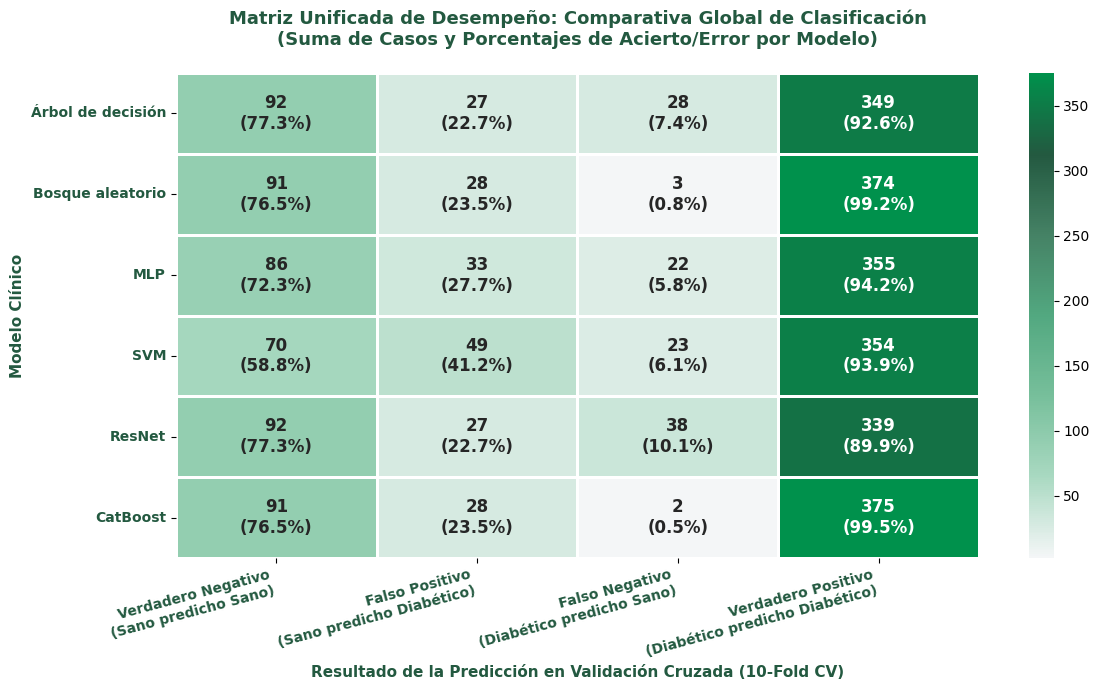

Matriz única integradora guardada con éxito en: resultados_6_modelos_10fold/matriz_unica_integradora_modelos.png


In [ ]:
# Bloque 5: dos matrices comparativas

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix
from matplotlib.colors import LinearSegmentedColormap

def plot_single_consolidated_matrix_all_models(filename):
    matrix_data = []

    # Extraer los datos de matriz de confusión para cada uno de los 6 modelos en variante pura
    for name in MODEL_ORDER:
        part = oof[oof["modelo"] == name]
        tn, fp, fn, tp = confusion_matrix(part["y_true"], part["pred_modelo"], labels=[0, 1]).ravel()

        matrix_data.append([
            tn,         # Verdadero Negativo
            fp,         # Falso Positivo
            fn,         # Falso Negativo
            tp          # Verdadero Positivo
        ])

    # Crear DataFrame para representar la matriz
    df_matrix = pd.DataFrame(
        matrix_data,
        index=MODEL_ORDER,
        columns=["Verdadero Negativo\n(Sano predicho Sano)",
                 "Falso Positivo\n(Sano predicho Diabético)",
                 "Falso Negativo\n(Diabético predicho Sano)",
                 "Verdadero Positivo\n(Diabético predicho Diabético)"]
    )

    # Crear el mapa de colores personalizado usando exactamente la paleta provista por el usuario
    # Ordenados desde tonos claros y suaves de la paleta hasta el más intenso y óptimo clínico (#00914C)
    colors_user = ["#F4F6F7", "#A9D9C1", "#77BF9B", "#52A880", "#458265", "#235940", "#00914C"]
    user_cmap = LinearSegmentedColormap.from_list("user_clinical_cmap", colors_user)

    plt.figure(figsize=(12, 7))

    # Usamos porcentajes respecto al total de la clase real para cada celda de anotación
    annot_labels = np.empty_like(df_matrix.values, dtype=object)
    for i, model_name in enumerate(MODEL_ORDER):
        part = oof[oof["modelo"] == model_name]
        tn, fp, fn, tp = confusion_matrix(part["y_true"], part["pred_modelo"], labels=[0, 1]).ravel()
        total_sanos = tn + fp
        total_diabeticos = tp + fn

        # Calcular porcentajes clínicos de forma exacta
        pct_tn = (tn / total_sanos) * 100
        pct_fp = (fp / total_sanos) * 100
        pct_fn = (fn / total_diabeticos) * 100
        pct_tp = (tp / total_diabeticos) * 100

        annot_labels[i, 0] = f"{tn}\n({pct_tn:.1f}%)"
        annot_labels[i, 1] = f"{fp}\n({pct_fp:.1f}%)"
        annot_labels[i, 2] = f"{fn}\n({pct_fn:.1f}%)"
        annot_labels[i, 3] = f"{tp}\n({pct_tp:.1f}%)"

    sns.heatmap(
        df_matrix,
        annot=annot_labels,
        fmt="",
        cmap=user_cmap,
        cbar=True,
        linewidths=2,
        linecolor="#FFFFFF",
        annot_kws={"fontsize": 12, "fontweight": "bold"}
    )

    plt.title("Matriz Unificada de Desempeño: Comparativa Global de Clasificación\n(Suma de Casos y Porcentajes de Acierto/Error por Modelo)",
              fontsize=13, fontweight="bold", pad=20, color="#235940")
    plt.ylabel("Modelo Clínico", fontsize=11, fontweight="bold", color="#235940")
    plt.xlabel("Resultado de la Predicción en Validación Cruzada (10-Fold CV)", fontsize=11, fontweight="bold", color="#235940")
    plt.xticks(rotation=15, ha="right", fontsize=10, fontweight="bold", color="#235940")
    plt.yticks(fontsize=10, fontweight="bold", color="#235940")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Matriz única integradora guardada con éxito en: {OUTPUT_DIR / filename}")

plot_single_consolidated_matrix_all_models("matriz_unica_integradora_modelos.png")

### **Gráficos de métricas**

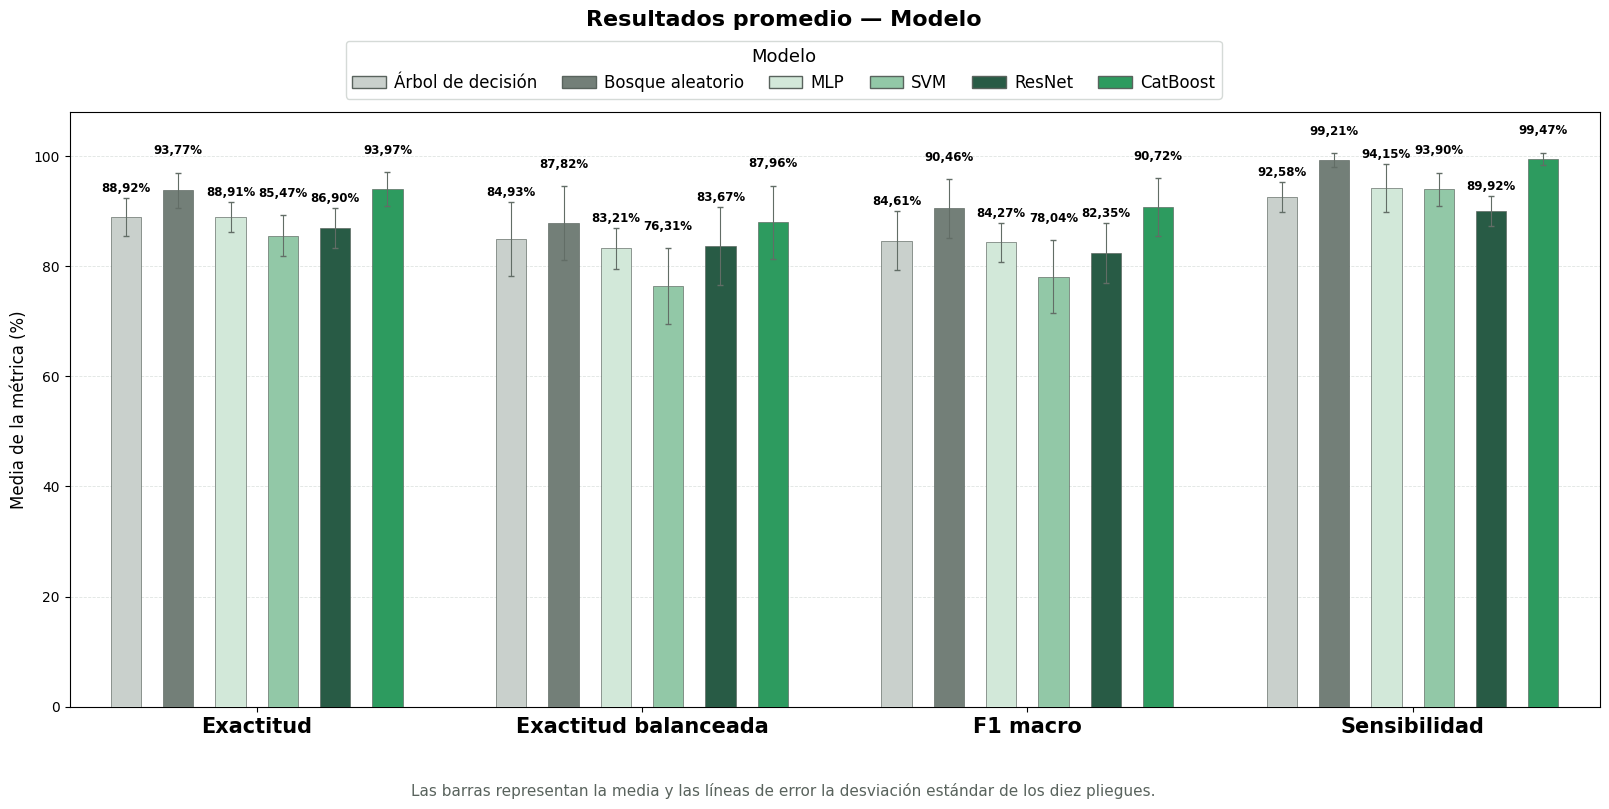

Gráfico guardado en: /content/grafico_modelo.png


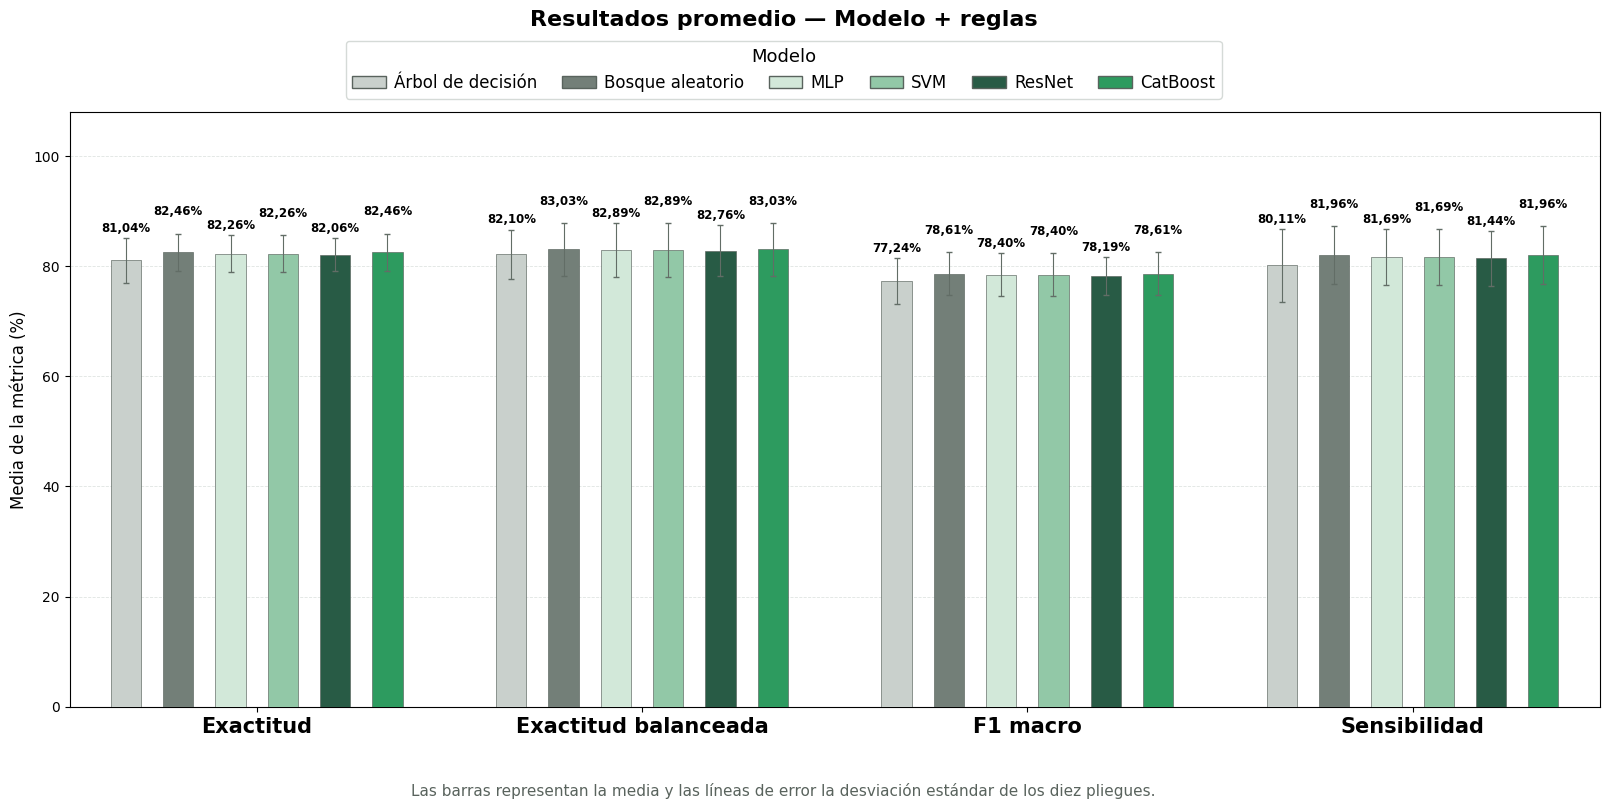

Gráfico guardado en: /content/grafico_modelo_mas_reglas.png


In [ ]:
# Bloque 6: gráficos de métricas por modelo y por variante

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ruta_csv = Path("/content/resultados_6_modelos_10fold/resumen_metricas_media_sd.csv")

if not ruta_csv.exists():
    encontrados = list(Path("/content").rglob("resumen_metricas_media_sd.csv"))
    if not encontrados:
        raise FileNotFoundError(
            "No se encontró 'resumen_metricas_media_sd.csv'. "
            "Asegúrate de haber ejecutado el Bloque 4."
        )
    ruta_csv = max(encontrados, key=lambda ruta: ruta.stat().st_mtime)

resultados = pd.read_csv(ruta_csv)

modelos = [
    "Árbol de decisión",
    "Bosque aleatorio",
    "MLP",
    "SVM",
    "ResNet",
    "CatBoost",
]

colores = {
    "Árbol de decisión": "#C9D0CC",
    "Bosque aleatorio": "#737F78",
    "MLP": "#D2E8D9",
    "SVM": "#92C8A7",
    "ResNet": "#285B45",
    "CatBoost": "#2D9B5F",
}

metricas = {
    "Exactitud": ("accuracy_media", "accuracy_sd"),
    "Exactitud balanceada": (
        "balanced_accuracy_media",
        "balanced_accuracy_sd",
    ),
    "F1 macro": ("F1_macro_media", "F1_macro_sd"),
    "Sensibilidad": ("recall_pos_media", "recall_pos_sd"),
}

variantes = ["Modelo", "Modelo + reglas"]

columnas_requeridas = {
    "variante",
    "modelo",
    *[columna for par in metricas.values() for columna in par],
}
faltan_columnas = columnas_requeridas.difference(resultados.columns)

if faltan_columnas:
    raise ValueError(
        f"Faltan columnas en el archivo de resultados: "
        f"{sorted(faltan_columnas)}"
    )

centros_metricas = np.arange(len(metricas)) * 1.40
ancho_barra = 0.11
separacion_barras = 0.19

alturas_etiquetas = [0.6, 2.8, 0.6, 2.8, 0.6, 2.8]
for variante in variantes:
    datos = resultados[resultados["variante"] == variante].copy()

    if datos.empty:
        raise ValueError(f"No hay resultados para la variante '{variante}'.")

    if datos["modelo"].duplicated().any():
        raise ValueError(
            f"Hay más de una fila por modelo para la variante '{variante}'."
        )

    datos = datos.set_index("modelo")
    faltan_modelos = [modelo for modelo in modelos if modelo not in datos.index]

    if faltan_modelos:
        raise ValueError(
            f"Faltan modelos para '{variante}': {faltan_modelos}"
        )

    fig, ax = plt.subplots(figsize=(17, 8.5))

    for i, modelo in enumerate(modelos):
        columnas_media = [par[0] for par in metricas.values()]
        columnas_sd = [par[1] for par in metricas.values()]

        medias = np.array(
            [datos.loc[modelo, columna] * 100 for columna in columnas_media],
            dtype=float,
        )
        desviaciones = np.array(
            [datos.loc[modelo, columna] * 100 for columna in columnas_sd],
            dtype=float,
        )

        desplazamiento = (
            i - (len(modelos) - 1) / 2
        ) * separacion_barras
        posiciones = centros_metricas + desplazamiento

        ax.bar(
            posiciones,
            medias,
            width=ancho_barra,
            color=colores[modelo],
            edgecolor="#59635D",
            linewidth=0.45,
            yerr=desviaciones,
            capsize=2,
            error_kw={
                "elinewidth": 0.8,
                "ecolor": "#626D66",
            },
            zorder=3,
        )

        for x, media, sd in zip(posiciones, medias, desviaciones):
            ax.text(
                x,
                media + sd + alturas_etiquetas[i],
                f"{media:.2f}%".replace(".", ","),
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
                rotation=0,
                clip_on=False,
            )

    ax.set_ylabel("Media de la métrica (%)", fontsize=12)
    ax.set_xticks(centros_metricas)
    ax.set_xticklabels(
        list(metricas.keys()),
        fontsize=15,
        fontweight="bold",
    )
    ax.set_xlim(centros_metricas[0] - 0.68, centros_metricas[-1] + 0.68)
    ax.set_ylim(0, 108)
    ax.set_yticks(np.arange(0, 101, 20))

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.6,
        color="#D8DEDA",
        alpha=0.8,
        zorder=0,
    )
    ax.set_axisbelow(True)

    elementos_leyenda = [
        Patch(
            facecolor=colores[modelo],
            edgecolor="#59635D",
            label=modelo,
        )
        for modelo in modelos
    ]

    fig.suptitle(
        f"Resultados promedio — {variante}",
        fontsize=16,
        fontweight="bold",
        y=0.95,
    )

    fig.legend(
        handles=elementos_leyenda,
        title="Modelo",
        loc="upper center",
        bbox_to_anchor=(0.5, 0.923),
        ncol=6,
        frameon=True,
        framealpha=1,
        edgecolor="#D5DAD7",
        fontsize=12,
        title_fontsize=13,
        columnspacing=1.5,
        handletextpad=0.5,
    )

    fig.text(
        0.5,
        0.025,
        "Las barras representan la media y las líneas de error la desviación "
        "estándar de los diez pliegues.",
        ha="center",
        fontsize=11,
        color="#59635D",
    )

    fig.subplots_adjust(
        top=0.83,
        bottom=0.13,
        left=0.08,
        right=0.98,
    )

    nombre_archivo = (
        "grafico_modelo.png"
        if variante == "Modelo"
        else "grafico_modelo_mas_reglas.png"
    )
    ruta_salida = Path("/content") / nombre_archivo

    fig.savefig(ruta_salida, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Gráfico guardado en: {ruta_salida}")

### **Gráficos de aciertos y desaciertos por clase**

=== TABLA DE MATRICES DE CONFUSIÓN (CONTEOS POR CLASE) ===


,modelo,variante,TN,FP,FN,TP
0,Árbol de decisión,Modelo,92,27,28,349
1,Árbol de decisión,Modelo + reglas,100,19,75,302
2,Bosque aleatorio,Modelo,91,28,3,374
3,Bosque aleatorio,Modelo + reglas,100,19,68,309
4,MLP,Modelo,86,33,22,355
5,MLP,Modelo + reglas,100,19,69,308
6,SVM,Modelo,70,49,23,354
7,SVM,Modelo + reglas,100,19,69,308
8,ResNet,Modelo,92,27,38,339
9,ResNet,Modelo + reglas,100,19,70,307



Tabla guardada exitosamente en: /content/resultados_6_modelos_10fold/matrices_confusion_conteos.csv


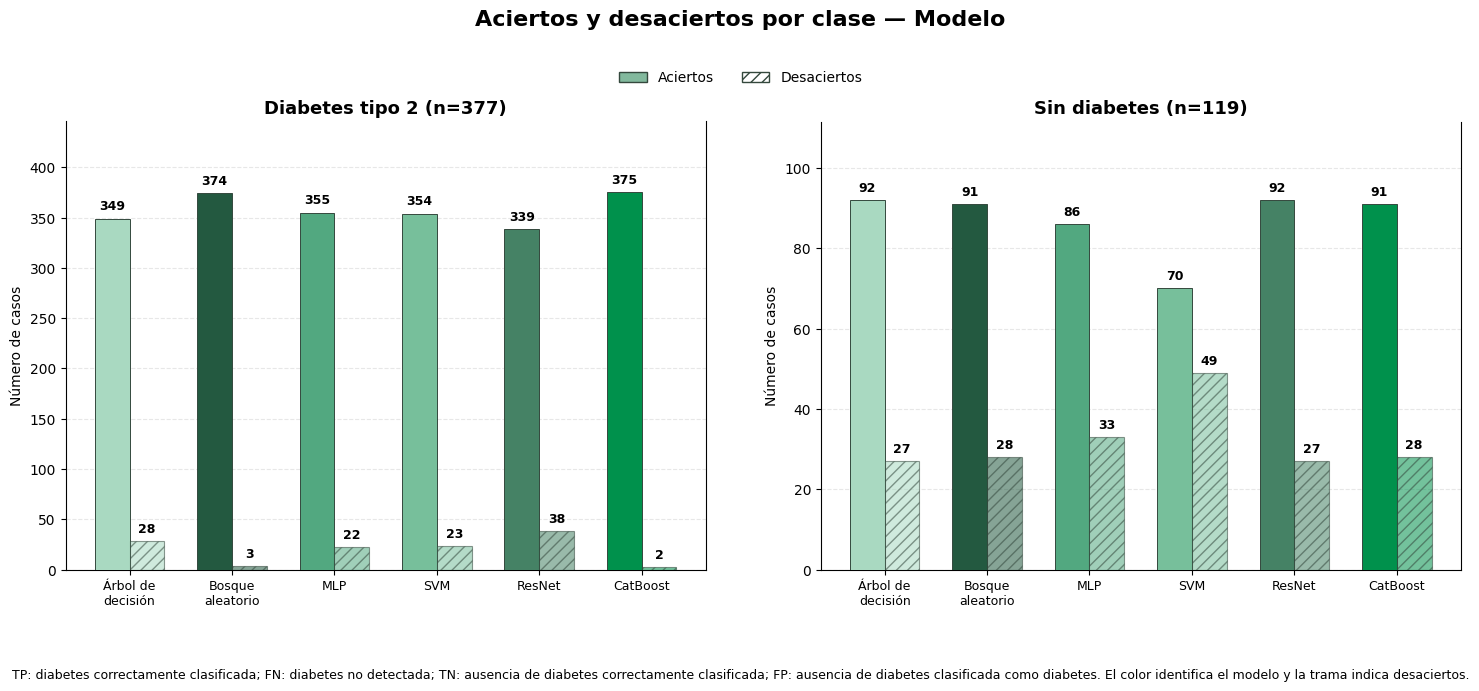

Gráfico guardado en: /content/resultados_6_modelos_10fold/aciertos_desaciertos_modelo.png


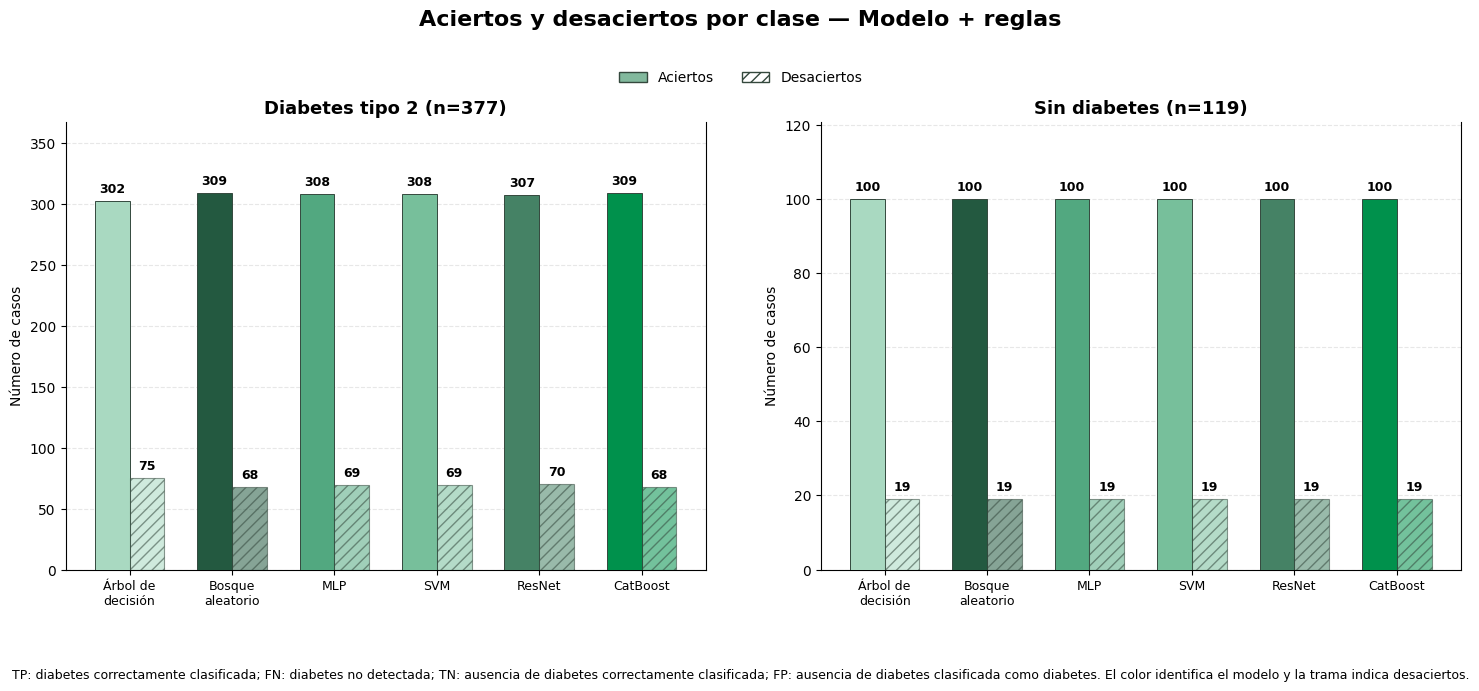

Gráfico guardado en: /content/resultados_6_modelos_10fold/aciertos_desaciertos_modelo_reglas.png


In [ ]:
# Bloque 7: Gráfico y tabla de aciertos y desaciertos

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix
from IPython.display import display

# Definir la carpeta de resultados estructurada
OUTPUT_DIR = Path("/content/resultados_6_modelos_10fold")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Buscar las predicciones fuera de muestra (oof) guardadas en el Bloque 4
ruta_csv = OUTPUT_DIR / "predicciones_oof_matrices.csv"

if not ruta_csv.exists():
    encontrados = list(Path("/content").rglob("predicciones_oof_matrices.csv"))
    if not encontrados:
        raise FileNotFoundError(
            "No se encontró 'predicciones_oof_matrices.csv'. "
            "Asegúrate de haber ejecutado el Bloque 4 previamente."
        )
    ruta_csv = max(encontrados, key=lambda ruta: ruta.stat().st_mtime)

oof_df = pd.read_csv(ruta_csv)

# Calcular dinámicamente las matrices de confusión (TN, FP, FN, TP) por modelo y variante
confusion_rows = []
modelos_lista = oof_df["modelo"].unique()
variantes_lista = ["Modelo", "Modelo + reglas"]

for modelo in modelos_lista:
    for variante in variantes_lista:
        sub = oof_df[oof_df["modelo"] == modelo]
        y_true = sub["y_true"].to_numpy()

        if variante == "Modelo":
            y_pred = sub["pred_modelo"].to_numpy()
        else:
            y_pred = sub["pred_modelo_reglas"].to_numpy()

        # confusion_matrix de sklearn devuelve: [[TN, FP], [FN, TP]] para clases binarias (0, 1)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

        confusion_rows.append({
            "modelo": modelo,
            "variante": variante,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

confusiones = pd.DataFrame(confusion_rows)

# Mostrar la tabla de conteos directamente en la salida de Colab
print("=== TABLA DE MATRICES DE CONFUSIÓN (CONTEOS POR CLASE) ===")
display(confusiones)

# Guardar la tabla de matrices de confusión en CSV para usarla en el bloque de TOPSIS
tabla_salida_csv = OUTPUT_DIR / "matrices_confusion_conteos.csv"
confusiones.to_csv(tabla_salida_csv, index=False, encoding="utf-8-sig")
print(f"\nTabla guardada exitosamente en: {tabla_salida_csv}")

modelos = [
    "Árbol de decisión",
    "Bosque aleatorio",
    "MLP",
    "SVM",
    "ResNet",
    "CatBoost",
]

colores = {
    "Árbol de decisión": "#A9D9C1",
    "Bosque aleatorio": "#235940",
    "MLP": "#52A880",
    "SVM": "#77BF9B",
    "ResNet": "#458265",
    "CatBoost": "#00914C",
}

columnas_conteo = ["TN", "FP", "FN", "TP"]
confusiones[columnas_conteo] = confusiones[columnas_conteo].astype(int)

variantes = ["Modelo", "Modelo + reglas"]
etiquetas_eje_x = {
    "Árbol de decisión": "Árbol de\ndecisión",
    "Bosque aleatorio": "Bosque\naleatorio",
    "MLP": "MLP",
    "SVM": "SVM",
    "ResNet": "ResNet",
    "CatBoost": "CatBoost",
}

for variante in variantes:
    datos = (
        confusiones[confusiones["variante"] == variante]
        .set_index("modelo")
        .reindex(modelos)
    )

    if datos[["TN", "FP", "FN", "TP"]].isna().any().any():
        raise ValueError(f"Faltan datos de uno o más modelos en «{variante}».")

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    paneles = [
        {
            "ax": axes[0],
            "titulo": "Diabetes tipo 2",
            "aciertos": "TP",
            "errores": "FN",
            "clase": 1,
        },
        {
            "ax": axes[1],
            "titulo": "Sin diabetes",
            "aciertos": "TN",
            "errores": "FP",
            "clase": 0,
        },
    ]

    x = np.arange(len(modelos))
    ancho = 0.34

    for panel in paneles:
        ax = panel["ax"]
        aciertos = datos[panel["aciertos"]].to_numpy()
        errores = datos[panel["errores"]].to_numpy()
        total_clase = int(aciertos[0] + errores[0])

        barras_aciertos = ax.bar(
            x - ancho / 2,
            aciertos,
            width=ancho,
            color=[colores[m] for m in modelos],
            edgecolor="#34483D",
            linewidth=0.7,
            zorder=3,
        )

        barras_errores = ax.bar(
            x + ancho / 2,
            errores,
            width=ancho,
            color=[colores[m] for m in modelos],
            edgecolor="#34483D",
            linewidth=0.8,
            hatch="///",
            alpha=0.55,
            zorder=3,
        )

        # Etiquetar cada barra con su conteo.
        for barras in [barras_aciertos, barras_errores]:
            for barra in barras:
                valor = int(barra.get_height())
                ax.annotate(
                    str(valor),
                    xy=(barra.get_x() + barra.get_width() / 2, valor),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=9,
                    fontweight="bold",
                )

        ax.set_title(
            f"{panel['titulo']} (n={total_clase})",
            fontsize=13,
            fontweight="bold",
        )
        ax.set_xticks(x)
        ax.set_xticklabels(
            [etiquetas_eje_x[m] for m in modelos],
            fontsize=9,
        )
        ax.set_ylabel("Número de casos")
        ax.set_ylim(0, max(aciertos.max(), errores.max()) * 1.18 + 3)
        ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)

    fig.suptitle(
        f"Aciertos y desaciertos por clase — {variante}",
        fontsize=16,
        fontweight="bold",
        y=0.98,
    )

    leyenda = [
        Patch(facecolor="#82B99D", edgecolor="#34483D", label="Aciertos"),
        Patch(
            facecolor="white",
            edgecolor="#34483D",
            hatch="///",
            label="Desaciertos",
        ),
    ]

    fig.legend(
        handles=leyenda,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.91),
        ncol=2,
        frameon=False,
    )

    fig.text(
        0.5,
        0.025,
        "TP: diabetes correctamente clasificada; FN: diabetes no detectada; "
        "TN: ausencia de diabetes correctamente clasificada; "
        "FP: ausencia de diabetes clasificada como diabetes. "
        "El color identifica el modelo y la trama indica desaciertos.",
        ha="center",
        fontsize=9,
    )

    fig.subplots_adjust(top=0.82, bottom=0.18, wspace=0.18)

    nombre = (
        "aciertos_desaciertos_modelo.png"
        if variante == "Modelo"
        else "aciertos_desaciertos_modelo_reglas.png"
    )
    ruta_salida = OUTPUT_DIR / nombre
    fig.savefig(ruta_salida, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Gráfico guardado en: {ruta_salida}")

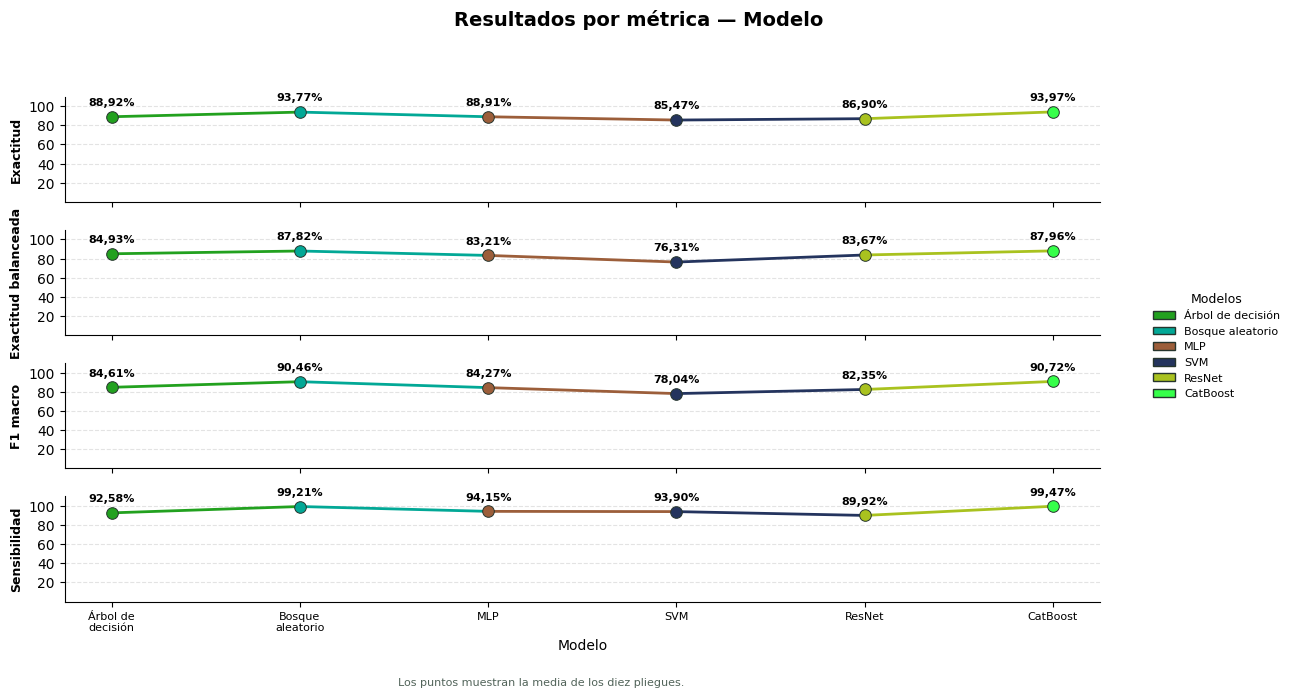

Gráfico guardado en: resultados_6_modelos_10fold/grafico_modelo.png


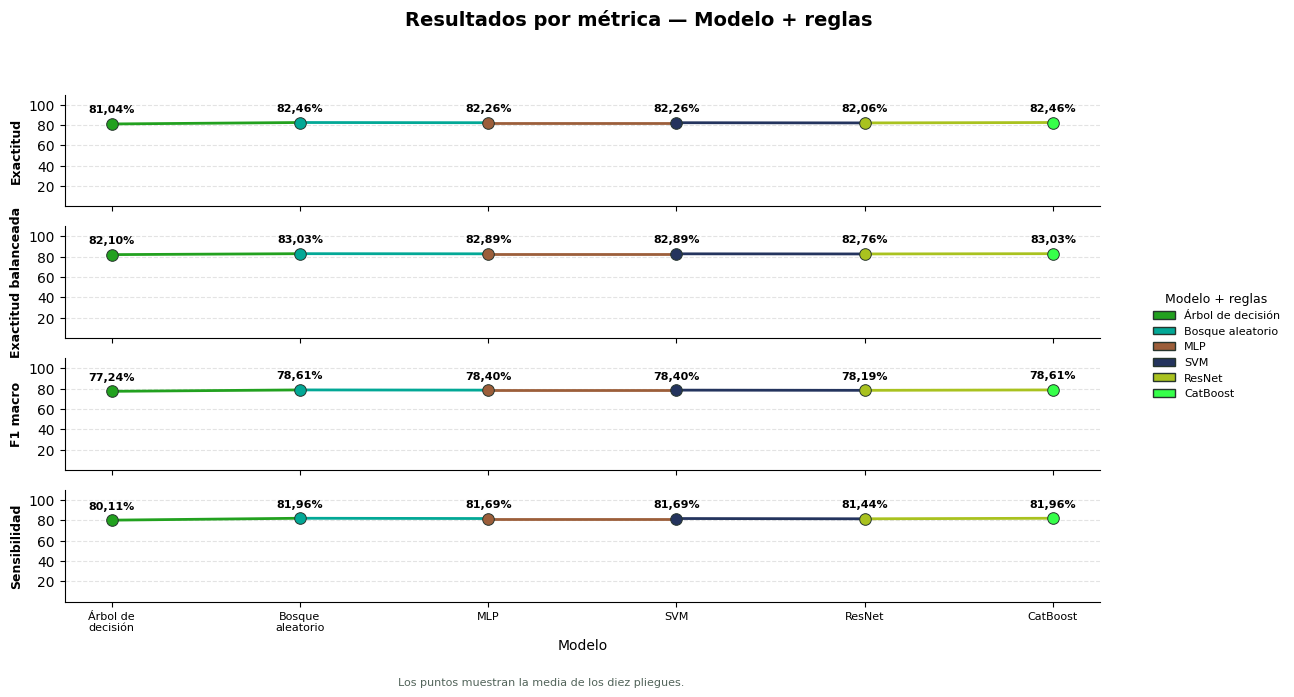

Gráfico guardado en: resultados_6_modelos_10fold/grafico_modelo_mas_reglas.png


In [ ]:
#Bloque 8 - Generación de gráfico tipo Lineas de rango
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import textwrap

OUTPUT_DIR = Path("resultados_6_modelos_10fold")
archivo_resumen = OUTPUT_DIR / "resumen_metricas_media_sd.csv"

if not archivo_resumen.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {archivo_resumen}")

resumen_graf = pd.read_csv(archivo_resumen)

orden_modelos = [
    "Árbol de decisión",
    "Bosque aleatorio",
    "MLP",
    "SVM",
    "ResNet",
    "CatBoost",
]

colores_modelos = {
    "Árbol de decisión": "#22A11F",
    "Bosque aleatorio": "#02A896",
    "MLP": "#9C5E3A",
    "SVM": "#24345E",
    "ResNet": "#A9C21F",
    "CatBoost": "#36FF4A",
}

metricas = [
    ("accuracy", "Exactitud"),
    ("balanced_accuracy", "Exactitud balanceada"),
    ("F1_macro", "F1 macro"),
    ("recall_pos", "Sensibilidad"),
]

def graficar_metricas(variante, nombre_archivo, titulo, titulo_leyenda):
    datos = resumen_graf[resumen_graf["variante"] == variante].copy()

    if datos.empty:
        raise ValueError(f"No hay resultados para la variante: {variante}")

    datos["modelo"] = pd.Categorical(
        datos["modelo"],
        categories=orden_modelos,
        ordered=True,
    )
    datos = datos.sort_values("modelo")

    posiciones = list(range(len(orden_modelos)))
    etiquetas_modelos = [
        "\n".join(textwrap.wrap(modelo, width=15))
        for modelo in orden_modelos
    ]

    fig, axes = plt.subplots(
        nrows=4,
        ncols=1,
        figsize=(14, 7),
        sharex=True,
    )

    for ax, (metrica, nombre) in zip(axes, metricas):
        medias = datos[f"{metrica}_media"].to_numpy() * 100

        # Conecta las medias consecutivas
        for i in range(len(posiciones) - 1):
            ax.plot(
                [posiciones[i], posiciones[i + 1]],
                [medias[i], medias[i + 1]],
                color=colores_modelos[orden_modelos[i]],
                linewidth=2,
                zorder=2,
            )

        # Puntos coloreados según el modelo
        for i, modelo in enumerate(orden_modelos):
            ax.scatter(
                posiciones[i],
                medias[i],
                color=colores_modelos[modelo],
                s=70,
                edgecolor="#26352D",
                linewidth=0.7,
                zorder=3,
            )

            etiqueta = f"{medias[i]:.2f}%".replace(".", ",")
            ax.annotate(
                etiqueta,
                (posiciones[i], medias[i]),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                fontweight="bold",
            )

        ax.set_ylabel(nombre, fontsize=9, fontweight="bold")
        ax.set_ylim(0, 105)
        ax.set_yticks([20, 40, 60, 80, 100])
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[-1].set_xticks(posiciones)
    axes[-1].set_xticklabels(etiquetas_modelos, fontsize=8)
    axes[-1].set_xlabel("Modelo", fontsize=10)

    # Recuadros de color para la leyenda
    elementos_leyenda = [
        Patch(
            facecolor=colores_modelos[modelo],
            edgecolor="#26352D",
            label=modelo,
        )
        for modelo in orden_modelos
    ]

    fig.suptitle(titulo, fontsize=14, fontweight="bold")
    fig.legend(
        handles=elementos_leyenda,
        title=titulo_leyenda,
        loc="center left",
        bbox_to_anchor=(0.86, 0.5),
        frameon=False,
        fontsize=8,
        title_fontsize=9,
    )

    fig.text(
        0.43,
        0.015,
        "Los puntos muestran la media de los diez pliegues.",
        ha="center",
        fontsize=8,
        color="#52645A",
    )

    fig.tight_layout(rect=[0.04, 0.04, 0.84, 0.93])

    ruta = OUTPUT_DIR / nombre_archivo
    fig.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Gráfico guardado en: {ruta}")

graficar_metricas(
    variante="Modelo",
    nombre_archivo="grafico_modelo.png",
    titulo="Resultados por métrica — Modelo",
    titulo_leyenda="Modelos",
)

graficar_metricas(
    variante="Modelo + reglas",
    nombre_archivo="grafico_modelo_mas_reglas.png",
    titulo="Resultados por métrica — Modelo + reglas",
    titulo_leyenda="Modelo + reglas",
)

### **MCDA - TOPSIS**

In [ ]:
# Bloque 9: MCDA mediante suma ponderada de cuatro métricas

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display


# Archivo generado en el Bloque 4
OUTPUT_DIR = Path("/content/resultados_6_modelos_10fold")
ruta_csv = OUTPUT_DIR / "resumen_metricas_media_sd.csv"

if not ruta_csv.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{ruta_csv}\n"
        "Ejecuta primero el Bloque 4."
    )

resultados = pd.read_csv(ruta_csv)


# Se usarán las medias de estas cuatro métricas.
metricas = {
    "Exactitud": "accuracy_media",
    "Exactitud balanceada": "balanced_accuracy_media",
    "F1 macro": "F1_macro_media",
    "Sensibilidad": "recall_pos_media",
}

modelos_esperados = [
    "Árbol de decisión",
    "Bosque aleatorio",
    "MLP",
    "SVM",
    "ResNet",
    "CatBoost",
]

variantes = ["Modelo", "Modelo + reglas"]

columnas_requeridas = [
    "modelo",
    "variante",
    *metricas.values(),
]

columnas_faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in resultados.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Faltan columnas en el archivo de resultados: {columnas_faltantes}"
    )


# Igual importancia para las cuatro métricas: 25% cada una.
pesos = {nombre: 0.25 for nombre in metricas}

print("Pesos utilizados en el MCDA:")
for nombre, peso in pesos.items():
    print(f"{nombre}: {peso:.0%}")


rankings = []

for variante in variantes:
    datos = resultados[resultados["variante"] == variante].copy()

    if datos.empty:
        raise ValueError(
            f"No se encontraron resultados para la variante «{variante}»."
        )

    datos["modelo"] = datos["modelo"].astype(str)

    modelos_encontrados = set(datos["modelo"])
    modelos_ausentes = [
        modelo for modelo in modelos_esperados
        if modelo not in modelos_encontrados
    ]

    if modelos_ausentes:
        raise ValueError(
            f"Faltan modelos en la variante «{variante}»: {modelos_ausentes}"
        )

    if datos["modelo"].duplicated().any():
        raise ValueError(
            f"Hay modelos duplicados en la variante «{variante}»."
        )

    for columna in metricas.values():
        datos[columna] = pd.to_numeric(datos[columna], errors="coerce")

    if datos[list(metricas.values())].isna().any().any():
        raise ValueError(
            f"Hay valores faltantes o no numéricos en las métricas "
            f"de la variante «{variante}»."
        )

    # Suma ponderada de las cuatro métricas.
    # Como todas están expresadas entre 0 y 1, se conserva esa escala.
    datos["Puntuación_MCDA"] = sum(
        datos[columna] * pesos[nombre]
        for nombre, columna in metricas.items()
    )

    datos["Puntuación_MCDA_%"] = datos["Puntuación_MCDA"] * 100

    datos = datos.sort_values(
        "Puntuación_MCDA",
        ascending=False,
    ).reset_index(drop=True)

    datos.insert(0, "Posición", np.arange(1, len(datos) + 1))
    datos.insert(1, "Variante", variante)

    columnas_salida = [
        "Posición",
        "Variante",
        "modelo",
        *metricas.values(),
        "Puntuación_MCDA",
        "Puntuación_MCDA_%",
    ]

    resultado_variante = datos[columnas_salida].copy()
    rankings.append(resultado_variante)

    print(f"\nRanking MCDA: {variante}")
    display(resultado_variante)


# Unir y guardar ambos rankings
ranking_final = pd.concat(rankings, ignore_index=True)

ruta_salida = OUTPUT_DIR / "ranking_mcda_4_metricas.csv"
ranking_final.to_csv(ruta_salida, index=False, encoding="utf-8-sig")

print(f"\nArchivo guardado en: {ruta_salida}")

Pesos utilizados en el MCDA:
Exactitud: 25%
Exactitud balanceada: 25%
F1 macro: 25%
Sensibilidad: 25%

Ranking MCDA: Modelo


,Posición,Variante,modelo,accuracy_media,balanced_accuracy_media,F1_macro_media,recall_pos_media,Puntuación_MCDA,Puntuación_MCDA_%
0,1,Modelo,CatBoost,0.939673,0.879565,0.907209,0.994737,0.930296,93.029606
1,2,Modelo,Bosque aleatorio,0.937673,0.878250,0.904595,0.992105,0.928156,92.815586
2,3,Modelo,Árbol de decisión,0.889224,0.849273,0.846081,0.925818,0.877599,87.759901
3,4,Modelo,MLP,0.889061,0.832096,0.842701,0.941465,0.876331,87.633087
4,5,Modelo,ResNet,0.868980,0.836730,0.823461,0.899218,0.857097,85.709707
5,6,Modelo,SVM,0.854735,0.763084,0.780446,0.939047,0.834328,83.432792



Ranking MCDA: Modelo + reglas


,Posición,Variante,modelo,accuracy_media,balanced_accuracy_media,F1_macro_media,recall_pos_media,Puntuación_MCDA,Puntuación_MCDA_%
0,1,Modelo + reglas,Bosque aleatorio,0.824612,0.830270,0.786063,0.819630,0.815144,81.514386
1,2,Modelo + reglas,CatBoost,0.824612,0.830270,0.786063,0.819630,0.815144,81.514386
2,3,Modelo + reglas,SVM,0.822571,0.828918,0.783999,0.816927,0.813104,81.310402
3,4,Modelo + reglas,MLP,0.822571,0.828918,0.783999,0.816927,0.813104,81.310402
4,5,Modelo + reglas,ResNet,0.820612,0.827638,0.781931,0.814367,0.811137,81.113696
5,6,Modelo + reglas,Árbol de decisión,0.810449,0.820988,0.772416,0.801067,0.801230,80.122999



Archivo guardado en: /content/resultados_6_modelos_10fold/ranking_mcda_4_metricas.csv


### **README**

In [ ]:
import os

readme_content = """# COMPARACIÓN DE MODELOS DE CLASIFICACIÓN PARA CASOS DE DIABETES TIPO 2

## Autores
1. Luz N. Ferrin R
2. Antonio F. L. Jacob Jr.

## Conjunto de datos
Este proyecto utiliza el conjunto de datos de Bangladesh de los autores [Buiyan et al. 2026].
El conjunto de datos está disponible en: https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv

---

## Descripción General
Este repositorio contiene el pipeline de experimentación, entrenamiento, evaluación clínica y análisis multi-criterio para clasificar pacientes con **Diabetes Tipo 2** utilizando variables clínicas y demográficas de entrada.

## Datos y Preprocesamiento
El conjunto de datos consta de **496 filas** distribuidas de la siguiente manera:
- **Clase 0 (Sanos):** 119 casos
- **Clase 1 (Diabéticos):** 377 casos

### Predictores (Features)
1. `No. of Pregnancy` (Número de embarazos)
2. `Age` (Edad)
3. `BMI` (Índice de Masa Corporal)
4. `BP(Systolic)` (Presión arterial sistólica)
5. `BP(Diastolic)` (Presión arterial diastólica)
6. `DiabetesPedigreeFunction` (Función de pedigrí de la diabetes)
7. `Insulin` (Nivel de insulina - imputado con la mediana del fold de entrenamiento)
8. `Skin Thickness(mm)` (Espesor del pliegue cutáneo)
9. `Glucose` (Glucosa plasmática en ayunas)

---

## Metodología de Validación
Se implementó un esquema robusto de **Validación Cruzada Estratificada de 10 pliegues (10-Fold CV)** para evitar la fuga de información (*data leakage*).
Para cada pliegue:
1. Se divide en **Entrenamiento (80%)**, **Validación (10%)** y **Prueba (10%)**.
2. La imputación de valores faltantes (usando la mediana) y el escalado de características (StandardScaler) se calculan **únicamente** sobre el conjunto de entrenamiento de cada pliegue y se aplican de forma idéntica a validación y prueba.

---

## Modelos Evaluados
Se entrenaron y compararon 6 clasificadores bajo dos variantes:

1. **Árbol de Decisión**
2. **Bosque Aleatorio (Random Forest)**
3. **MLP (Perceptrón Multicapa)**
4. **SVM (Máquinas de Soporte Vectorial)**
5. **ResNet Tabular** (Red neuronal profunda para datos tabulares)
6. **CatBoost**

### Variantes de Evaluación
- **Variante Pura (Modelo):** Las predicciones se basan exclusivamente en las salidas del clasificador entrenado.
- **Variante Híbrida (Modelo + Reglas):** Se aplica una regla clínica basada en la glucosa plasmática:
  - Si `Glucosa < 100` -> Se fuerza predicción a `0` (Sano).
  - Si `Glucosa >= 126` -> Se fuerza predicción a `1` (Diabético).
  - Si la glucosa se encuentra en el rango gris (`100 a 125`) -> Se conserva la predicción original del modelo.

---

## Resultados y Entregables

Todos los resultados métricos, parámetros y gráficos generados se estructuran dentro de la carpeta `resultados_6_modelos_10fold/`:

- `metricas_por_pliegue.csv`: Métricas detalladas para cada pliegue, modelo y variante.
- `resumen_metricas_media_sd.csv`: Promedios y desviaciones estándar globales.
- `predicciones_oof_matrices.csv`: Predicciones fuera de muestra (*Out-of-Fold*) acumuladas para el cálculo clínico global.
- `ranking_mcda_4_metricas.csv`: Ranking óptimo obtenido mediante análisis de decisión multi-criterio (MCDA) aplicando pesos iguales (25%) a Exactitud, Exactitud Balanceada, F1 Macro y Sensibilidad.
- `matrices_confusion_conteos.csv`: Conteo consolidado de aciertos y errores por clase.

### Gráficos Incluidos
- `matriz_unica_integradora_modelos.png`: Visualización consolidada del desempeño clínico con porcentajes relativos.
- `grafico_modelo.png` y `grafico_modelo_mas_reglas.png`: Gráficos de barras y perfiles de línea de rango de las métricas principales.
- `aciertos_desaciertos_modelo[_reglas].png`: Análisis comparativo de aciertos (TP, TN) y desaciertos (FP, FN) por modelo y variante.
"""

with open("resultados_6_modelos_10fold/README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("README.md actualizado con éxito con la información de los autores y el dataset de Bangladesh.")


README.md creado con éxito en /content y en la carpeta de resultados.


### **Descargar resultados en .zip**

In [ ]:
#Bloque 10 Descargar metricas y gráficos
from pathlib import Path
import zipfile
from google.colab import files

content_dir = Path("/content")
results_dir = content_dir / "resultados_6_modelos_10fold"
zip_path = content_dir / "resultados_6_modelos_10fold.zip"

if not results_dir.exists():
    raise FileNotFoundError(
        f"No se encontró la carpeta de resultados: {results_dir}"
    )

root_graphs = [
    "grafico_modelo.png",
    "grafico_modelo_mas_reglas.png",
    "aciertos_desaciertos_modelo.png",
    "aciertos_desaciertos_modelo_reglas.png",
]

with zipfile.ZipFile(zip_path, mode="w", compression=zipfile.ZIP_DEFLATED) as zip_file:
    # Incluye todos los archivos de la carpeta de resultados.
    for file_path in results_dir.rglob("*"):
        if file_path.is_file():
            zip_file.write(
                file_path,
                arcname=file_path.relative_to(content_dir),
            )

    # Incluye los gráficos que se guardaron directamente en /content.
    missing_graphs = []

    for filename in root_graphs:
        file_path = content_dir / filename

        if file_path.is_file():
            zip_file.write(file_path, arcname=f"graficos/{filename}")
        else:
            missing_graphs.append(filename)

print(f"ZIP creado: {zip_path}")
print(f"Tamaño: {zip_path.stat().st_size / (1024 * 1024):.2f} MB")

if missing_graphs:
    print("No se encontraron estos gráficos:")
    for filename in missing_graphs:
        print(f"- {filename}")

files.download(str(zip_path))

ZIP creado: /content/resultados_6_modelos_10fold.zip
Tamaño: 0.94 MB
No se encontraron estos gráficos:
- aciertos_desaciertos_modelo.png
- aciertos_desaciertos_modelo_reglas.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>